In [1]:
import os
import glob
import sys
import re
#import math
#import calendar
#from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import zipfile
import tempfile

#import matplotlib
#matplotlib.use("TkAgg")
#matplotlib.use('qtagg')
import matplotlib.pyplot as plt

#from scipy.optimize import curve_fit

from lidarpy.inversion import Klett
from lidarpy.molecular import AlphaBetaMolecular

In [ ]:
#readting the .nc output file
file_path = "output/201610/201610_klett_annual.nc"
ds = xr.open_dataset(file_path)
#print(ds)
time = ds["time"].data
coef_slope = ds["coef_slope"].data
#print(alpha_aer)
print(time[:6])
print(coef_slope[:6])

['2016-10-05T21:00:00.000000000' '2016-10-05T22:00:00.000000000'
 '2016-10-05T23:00:00.000000000' '2016-10-06T00:00:00.000000000'
 '2016-10-06T02:00:00.000000000' '2016-10-06T03:00:00.000000000']
[[ 7.51120022e+18  1.36475235e+04]
 [ 7.37674914e+18  8.36192045e+03]
 [ 1.40016791e+19  3.09953855e+03]
 [-8.79285082e+18  2.03094465e+04]
 [ 1.30966205e+19  6.09122652e+03]
 [ 1.01261311e+19  8.81101217e+03]]


[[1.40322590e+19 8.72549792e+03]
 [1.75717170e+19 6.93653127e+03]
 [1.90795875e+19 3.72138126e+03]
 [1.38943436e+19 9.16317964e+03]
 [1.13514648e+19 1.15663244e+04]
 [1.38127314e+19 9.79326694e+03]]
['2016-10-25T02:00:00.000000000' '2016-10-25T22:00:00.000000000'
 '2016-10-28T23:00:00.000000000' '2016-10-29T00:00:00.000000000'
 '2016-10-29T01:00:00.000000000' '2016-10-29T02:00:00.000000000']


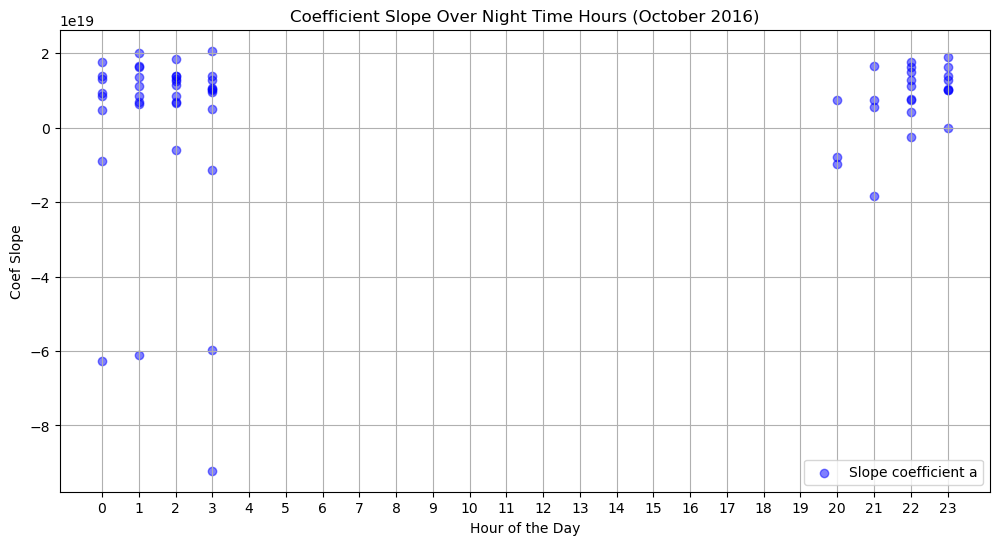

In [ ]:
# Make a filter of variable time to get only night time hours (from 20:00 to 04:00), time elements are in the format "YYYY-MM-DDTHH:MM:SS"
night_time = (pd.to_datetime(time).hour >= 20) | (pd.to_datetime(time).hour < 4)
coef_slope_night = coef_slope[night_time]
time_night = time[night_time]
print(coef_slope_night[-6:])
print(time_night[-6:])
# create array of only hour values from time_night
hours_night = pd.to_datetime(time_night).hour

plt.figure(figsize=(12, 6))
plt.scatter(hours_night, coef_slope_night[:, 0], label='Slope coefficient a', color='blue', alpha=0.5)
plt.xlabel('Hour of the Day')
plt.ylabel('Coef Slope')
plt.title('Coefficient Slope Over Night Time Hours (October 2016)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid()
plt.show()

[[1.40322590e+19 8.72549792e+03]
 [1.75717170e+19 6.93653127e+03]
 [1.90795875e+19 3.72138126e+03]
 [1.38943436e+19 9.16317964e+03]
 [1.13514648e+19 1.15663244e+04]
 [1.38127314e+19 9.79326694e+03]]
['2016-10-25T02:00:00.000000000' '2016-10-25T22:00:00.000000000'
 '2016-10-28T23:00:00.000000000' '2016-10-29T00:00:00.000000000'
 '2016-10-29T01:00:00.000000000' '2016-10-29T02:00:00.000000000']


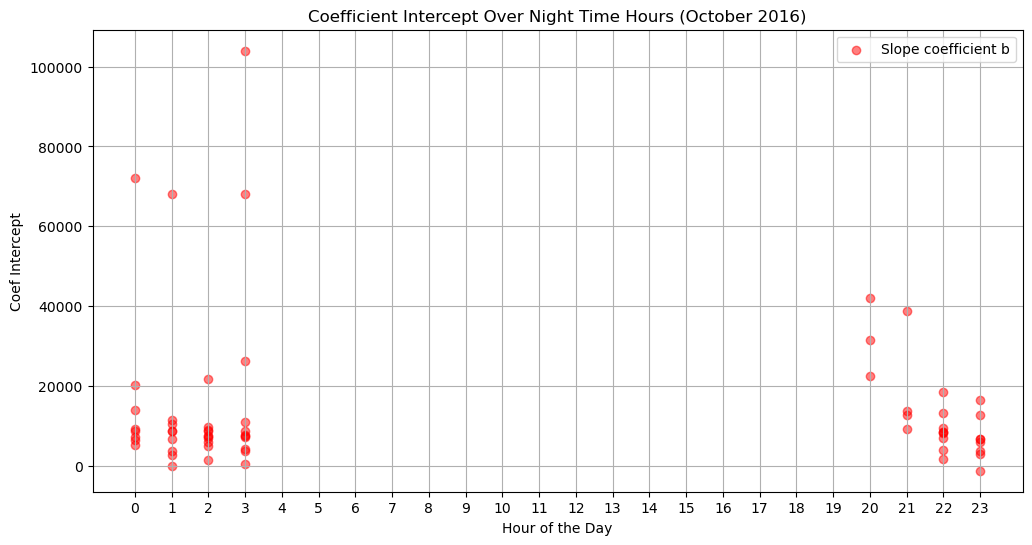

In [27]:
# Make a filter of variable time to get only night time hours (from 20:00 to 04:00), time elements are in the format "YYYY-MM-DDTHH:MM:SS"
night_time = (pd.to_datetime(time).hour >= 20) | (pd.to_datetime(time).hour < 4)
coef_slope_night = coef_slope[night_time]
time_night = time[night_time]
print(coef_slope_night[-6:])
print(time_night[-6:])
# create array of only hour values from time_night
hours_night = pd.to_datetime(time_night).hour

plt.figure(figsize=(12, 6))
plt.scatter(hours_night, coef_slope_night[:, 1], label='Slope coefficient b', color='red', alpha=0.5)
plt.xlabel('Hour of the Day')
plt.ylabel('Coef Intercept')
plt.title('Coefficient Intercept Over Night Time Hours (October 2016)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid()
plt.show()